# 01 – EDA: jakość danych trackingowych

Cel: sprawdzić, z czym pracujemy, zanim zbudujemy cechy i algorytmy.

**Zasada:** notebook pokazuje tylko podsumowania (procenty, liczby) i wykresy.
Nie wyświetlamy wierszy danych (`head()`, `print(frames)` itp.) — i nie wklejamy ich nigdzie poza naszym komputerem.

Wykresy zapisują się do `reports/eda/` (dodaj ten folder do `.gitignore`, jeśli nie chcecie ich w repo).

In [ ]:
import sys
from pathlib import Path

# notebook leży w notebooks/, a kod w src/ — dodajemy katalog główny repo do ścieżki
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from src.decoder.load import load_frames, team_of  # noqa: E402
from src.features.basic import _segments, frame_features, kinematics, slot_ids  # noqa: E402

MATCH = "BAR-ATH"
OUT = ROOT / "reports" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

PITCH_L, PITCH_W = 105.3, 68.0  # wg DATA.md


def save(fig, name):
    fig.savefig(OUT / f"{MATCH}_{name}.png", dpi=120, bbox_inches="tight")

In [11]:
frames = load_frames(MATCH)
teams = team_of(MATCH)
slots = slot_ids(frames)
fps = round(1 / np.median(np.diff(frames["t"].to_numpy())))

print(
    f"Klatki: {len(frames):,}   FPS: {fps}   Sloty: {len(slots)} "
    f"(home {sum(teams.get(s) == 'home' for s in slots)}, away {sum(teams.get(s) == 'away' for s in slots)})"
)
print(f"Klatki oceniane (graded): {frames['graded'].sum():,} ({frames['graded'].mean():.1%})")
print("Klatki w połowach:", frames["half"].value_counts(dropna=False).sort_index().to_dict())
print("Obrócone połowy:", frames.attrs.get("flipped"))

Klatki: 199,319   FPS: 25   Sloty: 46 (home 24, away 22)
Klatki oceniane (graded): 158,857 (79.7%)
Klatki w połowach: {1.0: 79467, 2.0: 79390, nan: 40462}
Obrócone połowy: {1: {'flipped': False, 'method': 'piłka+smart tagging', 'score': 25.9}, 2: {'flipped': True, 'method': 'piłka+smart tagging', 'score': -31.6}}


## 1. Ciągłość klatek
Czy `video_frame` idzie po kolei? Czy są dziury w czasie?

In [12]:
vf = frames["video_frame"].to_numpy()
jumps = np.diff(vf)
print(f"Odstępy między kolejnymi klatkami: {pd.Series(jumps).value_counts().head(5).to_dict()}")
print(
    f"Dziury (odstęp > 1): {(jumps > 1).sum()}, łącznie brakujących klatek: {(jumps[jumps > 1] - 1).sum():,}"
)
print(f"Duplikaty video_frame: {pd.Series(vf).duplicated().sum()}")
print(f"Ciągłe fragmenty (połowa + bez dziur): {_segments(frames).max()}")

Odstępy między kolejnymi klatkami: {1: 199318}
Dziury (odstęp > 1): 0, łącznie brakujących klatek: 0
Duplikaty video_frame: 0
Ciągłe fragmenty (połowa + bez dziur): 5


## 2. Braki piłki
Ile klatek bez piłki — ogółem, w połowach, w klatkach ocenianych — i jak długie są przerwy.

Brak piłki: wszystkie klatki 43.1%
            w połowach     40.7%
            graded         40.7%
            połowa 1      40.7%
            połowa 2      40.7%

Liczba przerw: 186
Długość przerw [s] – percentyle: {0.5: 9.22, 0.75: 20.42, 0.9: 33.6, 0.99: 221.41}
Przerwy < 0.5 s: 21.0%  (łatwe do uzupełnienia interpolacją)
Przerwy > 5 s:   76.3%  (tu raczej nie zgadujemy)


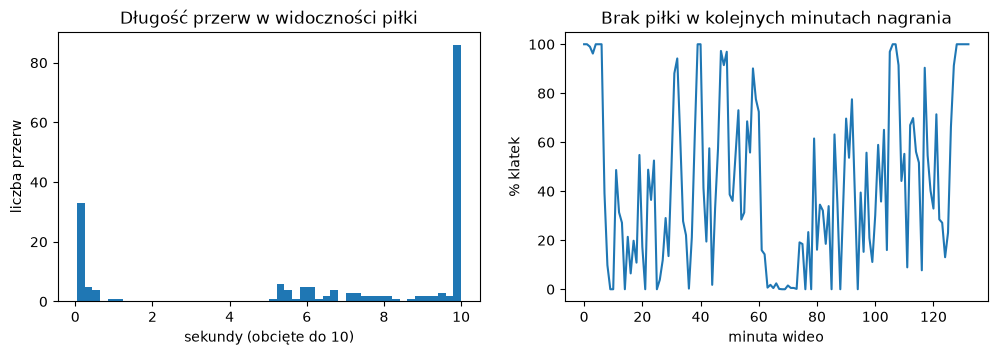

In [13]:
ball_missing = frames["ball_x"].isna()
print(f"Brak piłki: wszystkie klatki {ball_missing.mean():.1%}")
print(f"            w połowach     {ball_missing[frames['half'].notna()].mean():.1%}")
print(f"            graded         {ball_missing[frames['graded']].mean():.1%}")
for h in sorted(frames["half"].dropna().unique()):
    print(f"            połowa {int(h)}      {ball_missing[frames['half'] == h].mean():.1%}")

# długość ciągłych przerw w widoczności piłki (w sekundach)
run_id = (ball_missing != ball_missing.shift()).cumsum()
gaps = ball_missing.groupby(run_id).agg(["first", "size"])
gaps = gaps.loc[gaps["first"], "size"] / fps
print(f"\nLiczba przerw: {len(gaps):,}")
print("Długość przerw [s] – percentyle:", gaps.quantile([0.5, 0.75, 0.9, 0.99]).round(2).to_dict())
print(f"Przerwy < 0.5 s: {(gaps < 0.5).mean():.1%}  (łatwe do uzupełnienia interpolacją)")
print(f"Przerwy > 5 s:   {(gaps > 5).mean():.1%}  (tu raczej nie zgadujemy)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.clip(gaps, 0, 10), bins=50)
ax[0].set(
    title="Długość przerw w widoczności piłki",
    xlabel="sekundy (obcięte do 10)",
    ylabel="liczba przerw",
)
minute = (frames["t"] // 60).astype(int)
ax[1].plot(ball_missing.groupby(minute).mean() * 100)
ax[1].set(
    title="Brak piłki w kolejnych minutach nagrania", xlabel="minuta wideo", ylabel="% klatek"
)
save(fig, "ball_missing")

## 3. Zawodnicy i sloty
Ilu zawodników widać w klatce? Jak często sloty „znikają i wracają”?

Widoczni zawodnicy home – rozkład: {0: 0.005, 1: 0.005, 2: 0.01, 3: 0.009, 4: 0.01, 5: 0.009, 6: 0.007, 7: 0.015, 8: 0.028, 9: 0.058, 10: 0.223, 11: 0.542, 12: 0.075, 13: 0.003, 14: 0.0, 15: 0.001, 16: 0.001, 17: 0.0, 18: 0.0, 19: 0.0}
Widoczni zawodnicy away – rozkład: {1: 0.006, 2: 0.007, 3: 0.009, 4: 0.009, 5: 0.007, 6: 0.006, 7: 0.013, 8: 0.023, 9: 0.052, 10: 0.211, 11: 0.61, 12: 0.043, 13: 0.003, 14: 0.001, 15: 0.0}
Klatki z > 11 zawodnikami jednej drużyny (podejrzenie złej drużyny slotu): home 8.13%, away 4.74%

Sloty: mediana liczby odcinków 52, max 88
Sloty widoczne < 5% czasu: 3 z 46


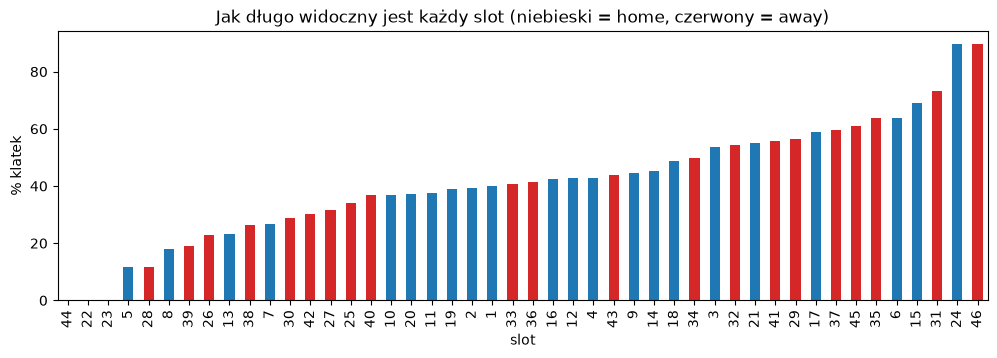

In [14]:
home_slots = [s for s in slots if teams.get(s) == "home"]
away_slots = [s for s in slots if teams.get(s) == "away"]
in_play = frames["half"].notna()

n_home = frames.loc[in_play, [f"{s}_x" for s in home_slots]].notna().sum(axis=1)
n_away = frames.loc[in_play, [f"{s}_x" for s in away_slots]].notna().sum(axis=1)
print(
    "Widoczni zawodnicy home – rozkład:",
    n_home.value_counts(normalize=True).sort_index().round(3).to_dict(),
)
print(
    "Widoczni zawodnicy away – rozkład:",
    n_away.value_counts(normalize=True).sort_index().round(3).to_dict(),
)
print(
    f"Klatki z > 11 zawodnikami jednej drużyny (podejrzenie złej drużyny slotu): "
    f"home {(n_home > 11).mean():.2%}, away {(n_away > 11).mean():.2%}"
)

# ile razy każdy slot pojawia się na nowo (liczba ciągłych odcinków) i jak długo żyje
rows = []
for s in slots:
    vis = frames[f"{s}_x"].notna().to_numpy()
    starts = np.flatnonzero(np.r_[vis[0], (~vis[:-1]) & vis[1:]])
    rows.append(
        {"slot": s, "team": teams.get(s), "odcinki": len(starts), "widoczny_%": vis.mean() * 100}
    )
life = pd.DataFrame(rows)
print(
    f"\nSloty: mediana liczby odcinków {life['odcinki'].median():.0f}, max {life['odcinki'].max()}"
)
print(f"Sloty widoczne < 5% czasu: {(life['widoczny_%'] < 5).sum()} z {len(life)}")

fig, ax = plt.subplots(figsize=(12, 3.5))
life.sort_values("widoczny_%").plot.bar(
    x="slot",
    y="widoczny_%",
    ax=ax,
    legend=False,
    color=life.sort_values("widoczny_%")["team"]
    .map({"home": "tab:blue", "away": "tab:red"})
    .fillna("gray"),
)
ax.set(
    title="Jak długo widoczny jest każdy slot (niebieski = home, czerwony = away)",
    ylabel="% klatek",
)
save(fig, "slots_visibility")

## 4. Zakresy: pozycje poza boiskiem
Margines 3 m — zawodnicy wychodzą trochę za linię (aut, rzut rożny), to normalne.

In [15]:
M = 3.0


def outside(x, y):
    return (x.abs() > PITCH_L / 2 + M) | (y.abs() > PITCH_W / 2 + M)


ball_out = outside(frames["ball_x"], frames["ball_y"])
print(f"Piłka poza boiskiem (+{M} m): {ball_out[~ball_missing].mean():.2%} klatek z widoczną piłką")
p_out = sum(outside(frames[f"{s}_x"], frames[f"{s}_y"]).sum() for s in slots)
p_all = sum(frames[f"{s}_x"].notna().sum() for s in slots)
print(f"Zawodnik poza boiskiem (+{M} m): {p_out / p_all:.3%} obserwacji")
xs_all = frames[[f"{s}_x" for s in slots]].to_numpy().ravel()
ys_all = frames[[f"{s}_y" for s in slots]].to_numpy().ravel()
print(
    f"Zakres x zawodników: {np.nanmin(xs_all):.1f} … {np.nanmax(xs_all):.1f} m (boisko ±{PITCH_L / 2:.2f})"
)
print(
    f"Zakres y zawodników: {np.nanmin(ys_all):.1f} … {np.nanmax(ys_all):.1f} m (boisko ±{PITCH_W / 2:.1f})"
)

Piłka poza boiskiem (+3.0 m): 2.01% klatek z widoczną piłką
Zawodnik poza boiskiem (+3.0 m): 0.287% obserwacji
Zakres x zawodników: -56.4 … 57.2 m (boisko ±52.65)
Zakres y zawodników: -39.2 … 39.6 m (boisko ±34.0)


## 5. Prędkości: czy tracking „skacze”?
Liczymy prędkość z surowych pozycji (bez wygładzania), żeby zobaczyć błędy.
Zawodnik > 12 m/s albo piłka > 40 m/s to prawie na pewno błąd trackingu.

Zawodnicy: mediana 1.28 m/s, 99.9 pct 12.9 m/s, > 12 m/s: 0.114%
Piłka:     mediana 5.54 m/s, 99.9 pct 84.7 m/s, > 40 m/s: 1.803%
Po wygładzeniu (src/features): zawodnicy mediana 1.27 m/s, 99 pct 6.5 m/s


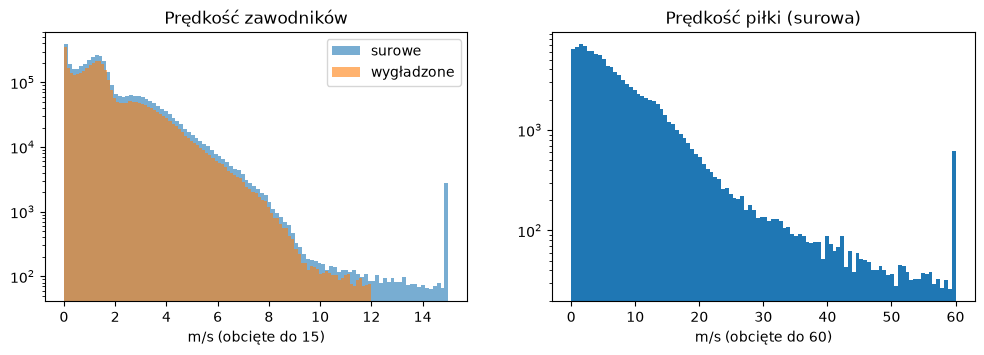

In [16]:
seg = _segments(frames)
same_seg = np.r_[False, seg[1:] == seg[:-1]]


def raw_speed(c):
    dx = frames[f"{c}_x"].diff().to_numpy()
    dy = frames[f"{c}_y"].diff().to_numpy()
    v = np.hypot(dx, dy) * fps
    v[~same_seg] = np.nan
    return v


pv = np.concatenate([raw_speed(s) for s in slots])
pv = pv[~np.isnan(pv)]
bv = raw_speed("ball")
bv = bv[~np.isnan(bv)]
print(
    f"Zawodnicy: mediana {np.median(pv):.2f} m/s, 99.9 pct {np.percentile(pv, 99.9):.1f} m/s, "
    f"> 12 m/s: {(pv > 12).mean():.3%}"
)
print(
    f"Piłka:     mediana {np.median(bv):.2f} m/s, 99.9 pct {np.percentile(bv, 99.9):.1f} m/s, "
    f"> 40 m/s: {(bv > 40).mean():.3%}"
)

kin = kinematics(frames)
sv = (
    kin[[c for c in kin.columns if c.endswith("_speed") and c != "ball_speed_calc"]]
    .to_numpy()
    .ravel()
)
sv = sv[~np.isnan(sv)]
print(
    f"Po wygładzeniu (src/features): zawodnicy mediana {np.median(sv):.2f} m/s, 99 pct {np.percentile(sv, 99):.1f} m/s"
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.clip(pv, 0, 15), bins=100, alpha=0.6, label="surowe")
ax[0].hist(np.clip(sv, 0, 15), bins=100, alpha=0.6, label="wygładzone")
ax[0].set(title="Prędkość zawodników", xlabel="m/s (obcięte do 15)", yscale="log")
ax[0].legend()
ax[1].hist(np.clip(bv, 0, 60), bins=100)
ax[1].set(title="Prędkość piłki (surowa)", xlabel="m/s (obcięte do 60)", yscale="log")
save(fig, "speeds")

## 6. Gdzie jest piłka i drużyny (sprawdzenie kierunku gry)
Po obróceniu połów Barcelona (home) zawsze atakuje w prawo, więc jej średnia pozycja
powinna być raczej po lewej (broni lewej bramki), a w ataku przesuwać się w prawo.

Połowa 1: średnie x home -4.1 m, away +8.8 m
Połowa 2: średnie x home -3.2 m, away +8.8 m


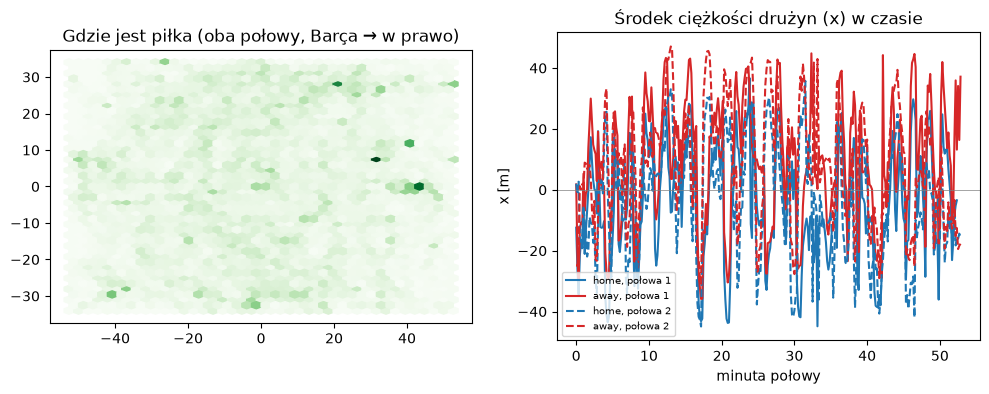

In [17]:
feat = frame_features(frames, teams)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ok = ~ball_missing & in_play
ax[0].hexbin(
    frames.loc[ok, "ball_x"],
    frames.loc[ok, "ball_y"],
    gridsize=40,
    cmap="Greens",
    extent=(-PITCH_L / 2, PITCH_L / 2, -PITCH_W / 2, PITCH_W / 2),
)
ax[0].set(title="Gdzie jest piłka (oba połowy, Barça → w prawo)", aspect="equal")
step = fps * 10  # jeden punkt co 10 s
for h, st in ((1, "-"), (2, "--")):
    m = frames["half"] == h
    minutes = ((frames.loc[m, "t"] - frames.loc[m, "t"].min()) / 60).iloc[::step]
    ax[1].plot(
        minutes,
        feat.loc[m, "home_cx"].iloc[::step],
        st,
        color="tab:blue",
        label=f"home, połowa {h}",
    )
    ax[1].plot(
        minutes, feat.loc[m, "away_cx"].iloc[::step], st, color="tab:red", label=f"away, połowa {h}"
    )
ax[1].axhline(0, color="gray", lw=0.5)
ax[1].set(title="Środek ciężkości drużyn (x) w czasie", xlabel="minuta połowy", ylabel="x [m]")
ax[1].legend(fontsize=7)
save(fig, "orientation_check")

for h in sorted(frames["half"].dropna().unique()):
    m = frames["half"] == h
    print(
        f"Połowa {int(h)}: średnie x home {feat.loc[m, 'home_cx'].mean():+.1f} m, "
        f"away {feat.loc[m, 'away_cx'].mean():+.1f} m"
    )

## 7. Najbliższy zawodnik do piłki (podgląd pod logikę posiadania)

Odległość najbliższego zawodnika do piłki – percentyle [m]: {0.25: 0.89, 0.5: 1.91, 0.75: 4.06, 0.9: 7.02}
Najbliższy w promieniu 1.5 m: 41.8% klatek z piłką
Drużyna najbliższego: {'home': 0.564, 'away': 0.436}


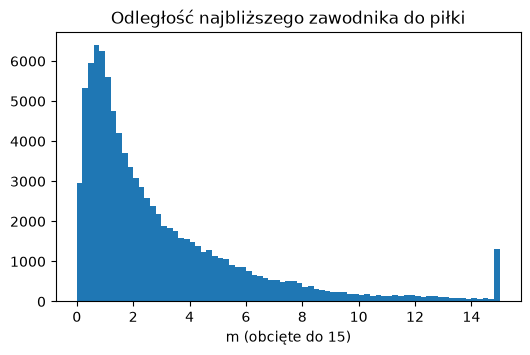

In [18]:
vis = feat["ball_visible"] & in_play
print(
    "Odległość najbliższego zawodnika do piłki – percentyle [m]:",
    feat.loc[vis, "nearest_dist"].quantile([0.25, 0.5, 0.75, 0.9]).round(2).to_dict(),
)
print(
    f"Najbliższy w promieniu 1.5 m: {(feat.loc[vis, 'nearest_dist'] < 1.5).mean():.1%} klatek z piłką"
)
print(
    "Drużyna najbliższego:",
    feat.loc[vis, "nearest_team"].value_counts(normalize=True).round(3).to_dict(),
)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.clip(feat.loc[vis, "nearest_dist"], 0, 15), bins=75)
ax.set(title="Odległość najbliższego zawodnika do piłki", xlabel="m (obcięte do 15)")
save(fig, "nearest_dist")

## 8. Wnioski

- **Piłka:** brak w 40,7% klatek ocenianych (obie połowy po równo). Braki to głównie długie bloki: 76% przerw > 5 s (mediana 9 s), tylko 21% < 0,5 s → interpolacja pomoże niewiele; posiadanie musi działać bez piłki (`frames_since_ball_seen`, ustawienie zawodników).
- **Hipoteza:** długie przerwy w widoczności piłki mogą pokrywać się z martwą piłką (do sprawdzenia na publicznych danych Metrica).
- **Sloty:** slot ≠ zawodnik. 3/46 slotów prawie niewidocznych, większość widoczna 20–70% czasu; tylko 2 sloty (~90%, prawdopodobnie bramkarze) są stabilne → cechy liczymy na poziomie drużyny, nie gracza.
- **Prędkości zawodników:** surowe > 12 m/s tylko 0,11% → tracking zawodników czysty, wygładzanie wystarcza.
- **Prędkość piłki:** surowo 1,8% > 40 m/s (maks. ~85 m/s). Pojedynczych skoków prawie brak (czyszczenie usuwa tylko 15 klatek) — to raczej „teleporty” piłki po ponownym wykryciu. Pozycje są OK, a nierealne prędkości w momencie przeskoku odcina limit 40 m/s (po czyszczeniu 99,9 pct = 39 m/s).
- **Kierunek gry:** po obróceniu połów Barcelona średnio x < 0, Athletic x > 0 w obu połowach → obrót poprawny.
- **Mapa piłki:** wyraźne punkty, gdzie piłka stoi długo (stałe fragmenty) → potencjalny sygnał dla martwej piłki.